In [1]:
import sys
print(sys.executable)

d:\Pune-House-Price-Prediction\.venv\Scripts\python.exe


In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

# Locate the project directory
project_root = Path.cwd().parent

# Load the cleaned dataset
cleaned_file = project_root / "data" / "processed" / "pune_property_cleaned.csv"
df = pd.read_csv(cleaned_file)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())


Dataset loaded successfully!
Shape: (29680, 29)


,additionalrooms,age,amenitiesavailable,amenitiesnot,area,balconies,bathroom,bhk,carpetarea,facing,floor,locality,neworold,opensides,overlooking,ownership,possesiondate,price,pricepersquare,projectname,roadfaceing,status,totalfloor,bhk_count,property_type,floor_number,road_width_feet,property_age_years,possession_date
0,NaN,2 - 3 years,"Lift Available,Car Parking,Power Backup,Indoor...","24 X 7 Security,Children's play area,Club Hous...","1,611.00",2.00,3.00,3 BHK Apartment,"1,209.00",West,"3,",Deccan Gymkhana,New,2.00,Road View,Co-Operative Society,NaN,27000000,16759,Bhansali Prive Rio,40 feet,Ready to move,6.00,3.00,Apartment,3.00,40.00,2.50,NaN
1,NaN,0 - 1 year,"Lift Available,Car Parking,Power Backup,24 X 7...","Children's play area,Sports Facility,Landscape...","1,279.00",NaN,2.00,2 BHK Apartment,NaN,NorthEast,1,Kharadi,New,NaN,NaN,Freehold,NaN,7610050,5950,Goel Ganga Platino,NaN,Ready to move,NaN,2.00,Apartment,1.00,NaN,0.50,NaN
2,NaN,0 - 1 year,"Lift Available,Car Parking,Power Backup,24 X 7...",Sports Facility,670.00,NaN,1.00,1 BHK Apartment,NaN,NorthEast,1,Sus,New,NaN,NaN,Freehold,NaN,4100000,6119,Vilas Javdekar Yashwin,NaN,Ready to move,NaN,1.00,Apartment,1.00,NaN,0.50,NaN
3,NaN,2 - 3 years,"Lift Available,Car Parking,Power Backup,24 X 7...","Sports Facility,Landscaped Gardens",956.00,NaN,2.00,2 BHK Apartment,615.00,NorthEast,1,Bavdhan,New,NaN,NaN,Freehold,NaN,5736000,6000,Rohan Ishan,NaN,Ready to move,NaN,2.00,Apartment,1.00,NaN,2.50,NaN
4,NaN,0 - 1 year,"Lift Available,Car Parking,Power Backup,24 X 7...","Club House,Swimming Pool,Sports Facility,Joggi...","1,706.00",1.00,3.00,3 BHK Apartment,"1,195.00",West,"6,",Deccan Gymkhana,New,2.00,Road View,Freehold,NaN,29002000,17000,Swojas Aavishkar,60 feet,Ready to move,9.00,3.00,Apartment,6.00,60.00,0.50,NaN


In [3]:

# Dataset structure
df.info()

# Summary statistics for numeric columns
display(df.describe().T)

# Count unique values in each column
display(df.nunique().sort_values(ascending=False).to_frame("unique_values"))


<class 'pandas.DataFrame'>
RangeIndex: 29680 entries, 0 to 29679
Data columns (total 29 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   additionalrooms     7317 non-null   str    
 1   age                 22468 non-null  str    
 2   amenitiesavailable  27582 non-null  str    
 3   amenitiesnot        27093 non-null  str    
 4   area                29667 non-null  float64
 5   balconies           17725 non-null  float64
 6   bathroom            27826 non-null  float64
 7   bhk                 29680 non-null  str    
 8   carpetarea          6547 non-null   float64
 9   facing              24750 non-null  str    
 10  floor               25701 non-null  str    
 11  locality            29680 non-null  str    
 12  neworold            29680 non-null  str    
 13  opensides           8437 non-null   float64
 14  overlooking         13559 non-null  str    
 15  ownership           22801 non-null  str    
 16  possesiondate  

,count,mean,std,min,25%,50%,75%,max
area,"29,667.00","1,789.88","1,989.72",150.00,988.00,"1,315.00","2,000.00","60,000.00"
balconies,"17,725.00",1.73,0.76,1.00,1.00,2.00,2.00,8.00
bathroom,"27,826.00",2.55,1.06,1.00,2.00,2.00,3.00,9.00
carpetarea,"6,547.00","1,032.74",625.13,100.00,660.00,877.00,"1,184.50","7,104.00"
opensides,"8,437.00",2.16,1.16,1.00,1.00,2.00,3.00,4.00
price,"29,680.00","15,195,240.25","17,368,978.45","100,000.00","5,850,000.00","8,900,000.00","16,982,821.75","269,000,000.00"
pricepersquare,"29,680.00","7,834.85","3,715.84",100.00,"5,571.00","6,915.50","9,151.25","91,549.00"
totalfloor,"19,407.00",10.08,5.03,1.00,7.00,10.00,12.00,35.00
bhk_count,"29,035.00",2.55,0.97,0.00,2.00,2.00,3.00,8.00
floor_number,"25,701.00",4.63,3.41,0.00,2.00,4.00,7.00,34.00


,unique_values
pricepersquare,7085
amenitiesavailable,6401
projectname,3589
price,3341
amenitiesnot,2533
area,2379
carpetarea,1231
locality,502
roadfaceing,83
road_width_feet,83


Price summary:


count        29,680.00
mean     15,195,240.25
std      17,368,978.45
min         100,000.00
25%       5,850,000.00
50%       8,900,000.00
75%      16,982,821.75
max     269,000,000.00
Name: price, dtype: float64

Price skewness: 3.18


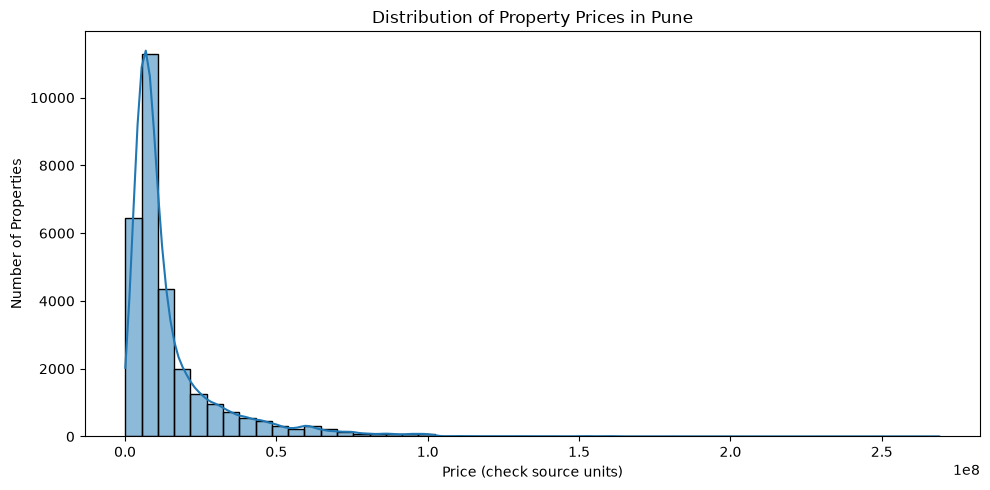

In [4]:

print("Price summary:")
display(df["price"].describe())

print("Price skewness:", round(df["price"].skew(), 2))

plt.figure(figsize=(10, 5))
sns.histplot(df["price"], bins=50, kde=True)
plt.title("Distribution of Property Prices in Pune")
plt.xlabel("Price (check source units)")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.show()


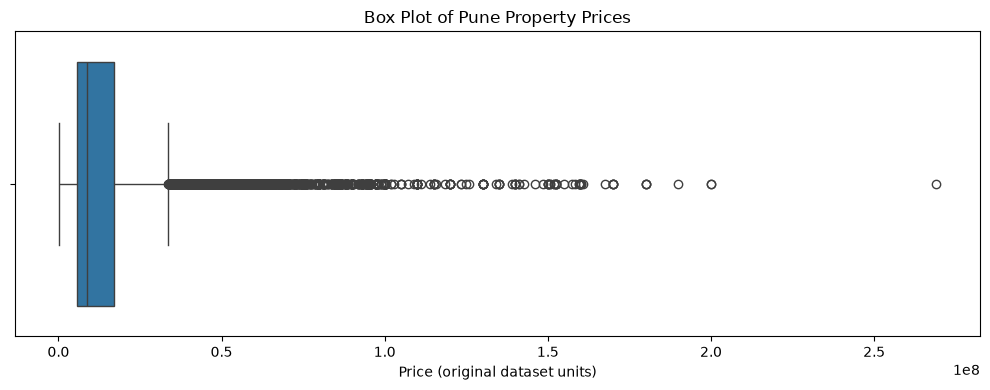

In [5]:

plt.figure(figsize=(10, 4))

sns.boxplot(x=df["price"])

plt.title("Box Plot of Pune Property Prices")
plt.xlabel("Price (original dataset units)")
plt.tight_layout()
plt.show()


In [6]:

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

potential_outliers = df[
    (df["price"] < lower_bound) |
    (df["price"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower boundary:", lower_bound)
print("Upper boundary:", upper_bound)
print("Potential outlier rows:", len(potential_outliers))
print("Percentage of dataset:", round(len(potential_outliers) / len(df) * 100, 2), "%")

display(potential_outliers[["price", "locality", "bhk", "area"]].head(10))


Q1: 5850000.0
Q3: 16982821.75
IQR: 11132821.75
Lower boundary: -10849232.625
Upper boundary: 33682054.375
Potential outlier rows: 3202
Percentage of dataset: 10.79 %


,price,locality,bhk,area
80,35000000,Baner,4 BHK Apartment,"3,030.00"
92,56122710,Bhugaon,5 BHK Villa,"6,737.00"
93,66768000,Shivaji Nagar,4 BHK Apartment,"4,173.00"
137,47500000,Baner,4 BHK Apartment,"3,575.00"
142,64800000,Model Colony,4 BHK Apartment,"3,375.00"
150,75000000,Bopodi,4 BHK Apartment,"4,000.00"
155,45000000,Baner,4 BHK Apartment,"3,690.00"
195,62400000,Shivaji Nagar,4 BHK Apartment,"3,864.00"
196,61920000,Shivaji Nagar,4 BHK Apartment,"3,870.00"
203,44609930,Pashan,3 BHK Apartment,"2,738.00"


In [7]:

# Compare potential outliers with the rest of the dataset

upper_bound = Q3 + 1.5 * IQR

df["price_group"] = np.where(
    df["price"] > upper_bound,
    "Potential outlier",
    "Regular range"
)

comparison = df.groupby("price_group").agg(
    property_count=("price", "size"),
    average_price=("price", "mean"),
    median_price=("price", "median"),
    average_area=("area", "mean"),
    median_area=("area", "median")
).round(2)

display(comparison)


,property_count,average_price,median_price,average_area,median_area
price_group,,,,,
Potential outlier,3202,"56,192,764.59","50,000,000.00","4,093.54","3,981.00"
Regular range,26478,"10,237,385.70","8,000,000.00","1,511.16","1,230.00"


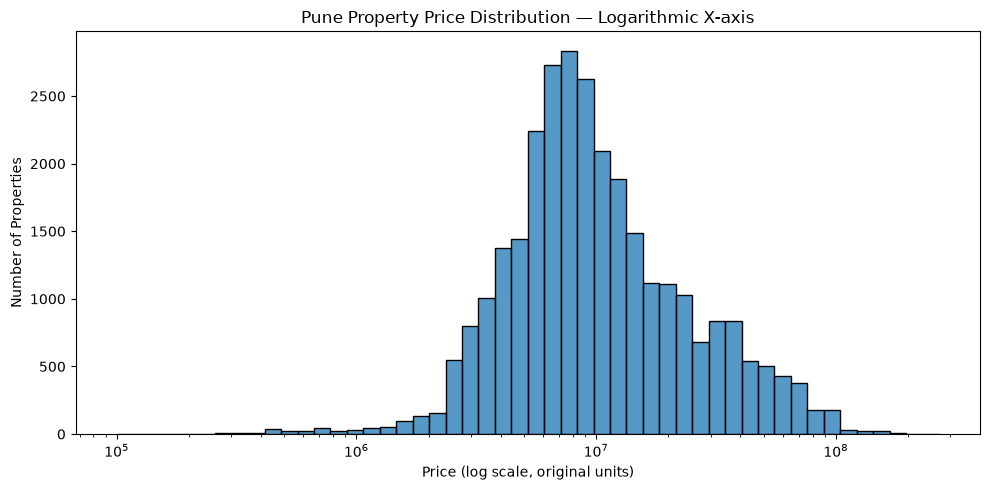

In [8]:

plt.figure(figsize=(10, 5))

sns.histplot(df["price"], bins=50, log_scale=(True, False))

plt.title("Pune Property Price Distribution — Logarithmic X-axis")
plt.xlabel("Price (log scale, original units)")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.show()


In [9]:

print("Area summary:")
display(df["area"].describe())

print("Area skewness:", round(df["area"].skew(), 2))

print("Missing area values:", df["area"].isna().sum())


Area summary:


count   29,667.00
mean     1,789.88
std      1,989.72
min        150.00
25%        988.00
50%      1,315.00
75%      2,000.00
max     60,000.00
Name: area, dtype: float64

Area skewness: 11.91
Missing area values: 13


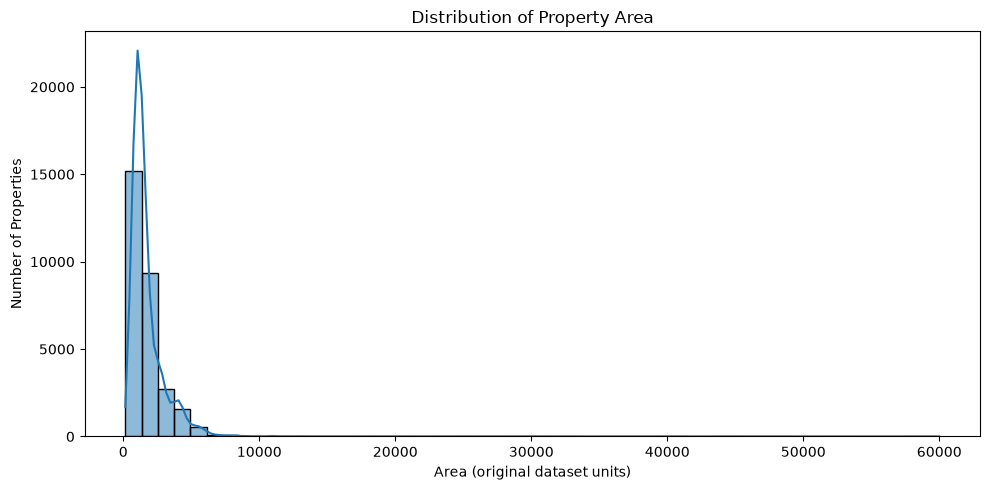

In [10]:

plt.figure(figsize=(10, 5))

sns.histplot(df["area"].dropna(), bins=50, kde=True)

plt.title("Distribution of Property Area")
plt.xlabel("Area (original dataset units)")
plt.ylabel("Number of Properties")
plt.tight_layout()
plt.show()


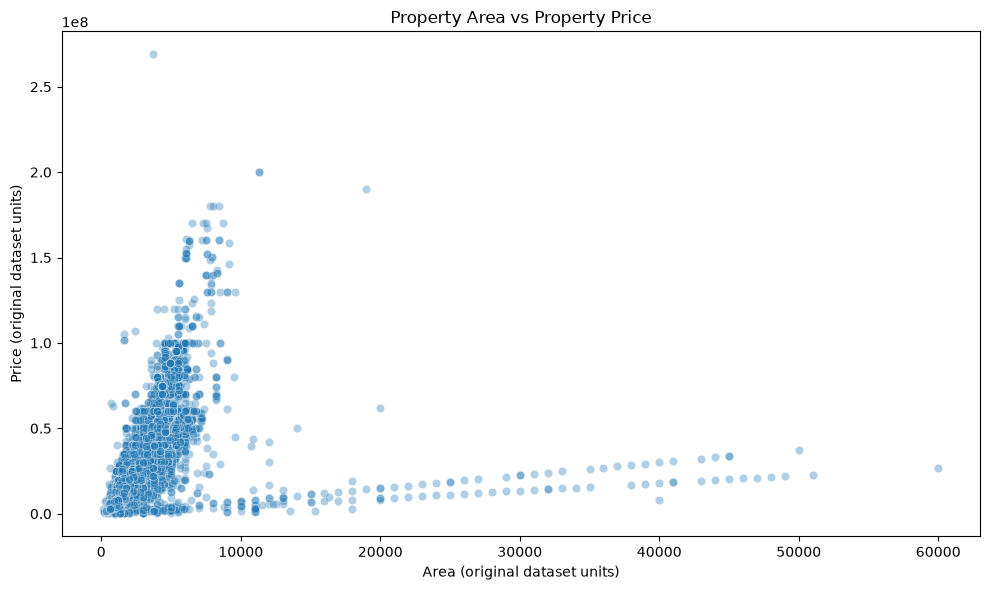

In [11]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="area",
    y="price",
    alpha=0.35
)

plt.title("Property Area vs Property Price")
plt.xlabel("Area (original dataset units)")
plt.ylabel("Price (original dataset units)")
plt.tight_layout()
plt.show()


In [12]:

# Inspect the largest property areas
area_check = (
    df.nlargest(20, "area")[
        ["area", "price", "locality", "bhk", "carpetarea", "property_type"]
    ]
)

display(area_check.to_string(index=False))


'     area    price  locality              bhk  carpetarea    property_type\n60,000.00 27000000 Chandkhed Residential Plot         NaN Residential Plot\n51,000.00 22950000 Chandkhed Residential Plot         NaN Residential Plot\n50,000.00 37500000 Hinjewadi Residential Plot         NaN Residential Plot\n49,000.00 22050000 Chandkhed Residential Plot         NaN Residential Plot\n48,000.00 21600000 Chandkhed Residential Plot         NaN Residential Plot\n47,000.00 21150000 Chandkhed Residential Plot         NaN Residential Plot\n46,000.00 20700000 Chandkhed Residential Plot         NaN Residential Plot\n45,000.00 33750000      Nere Residential Plot         NaN Residential Plot\n45,000.00 20250000 Chandkhed Residential Plot         NaN Residential Plot\n45,000.00 33750000 Hinjewadi Residential Plot         NaN Residential Plot\n44,000.00 33000000      Nere Residential Plot         NaN Residential Plot\n44,000.00 19800000 Chandkhed Residential Plot         NaN Residential Plot\n43,000.00 3

In [13]:

area_data = df["area"].dropna()

area_q1 = area_data.quantile(0.25)
area_q3 = area_data.quantile(0.75)
area_iqr = area_q3 - area_q1

area_upper_bound = area_q3 + 1.5 * area_iqr

area_outliers = df[df["area"] > area_upper_bound]

print("Area Q1:", area_q1)
print("Area Q3:", area_q3)
print("Area IQR:", area_iqr)
print("Upper boundary:", area_upper_bound)
print("Potential area outliers:", len(area_outliers))
print(
    "Percentage:",
    round(len(area_outliers) / len(df) * 100, 2),
    "%"
)

display(
    area_outliers.nlargest(10, "area")[
        ["area", "price", "locality", "bhk"]
    ]
)


Area Q1: 988.0
Area Q3: 2000.0
Area IQR: 1012.0
Upper boundary: 3518.0
Potential area outliers: 2760
Percentage: 9.3 %


,area,price,locality,bhk
1756,"60,000.00",27000000,Chandkhed,Residential Plot
1530,"51,000.00",22950000,Chandkhed,Residential Plot
1765,"50,000.00",37500000,Hinjewadi,Residential Plot
1074,"49,000.00",22050000,Chandkhed,Residential Plot
1076,"48,000.00",21600000,Chandkhed,Residential Plot
1075,"47,000.00",21150000,Chandkhed,Residential Plot
864,"46,000.00",20700000,Chandkhed,Residential Plot
393,"45,000.00",33750000,Nere,Residential Plot
1078,"45,000.00",20250000,Chandkhed,Residential Plot
1764,"45,000.00",33750000,Hinjewadi,Residential Plot


In [14]:

# Compare property types
property_type_summary = (
    df.groupby("property_type", dropna=False)
    .agg(
        property_count=("price", "size"),
        median_price=("price", "median"),
        median_area=("area", "median"),
        average_price=("price", "mean")
    )
    .sort_values("property_count", ascending=False)
)

display(property_type_summary.head(15).round(2))


,property_count,median_price,median_area,average_price
property_type,,,,
Apartment,26408,"8,500,000.00","1,251.00","14,573,673.58"
Villa,1670,"20,000,000.00","2,500.00","26,643,073.69"
Residential Plot,645,"1,950,000.00","2,700.00","7,389,047.98"
Independent House,458,"13,500,000.00","1,967.50","20,544,728.56"
Independent Floor,345,"5,802,500.00","1,010.00","9,641,316.01"
penthouse,147,"19,500,000.00","2,575.00","27,748,979.59"
studio apartment,5,"2,200,000.00",350.00,"3,490,000.00"
Other Residential,2,"20,500,000.00","2,850.00","20,500,000.00"


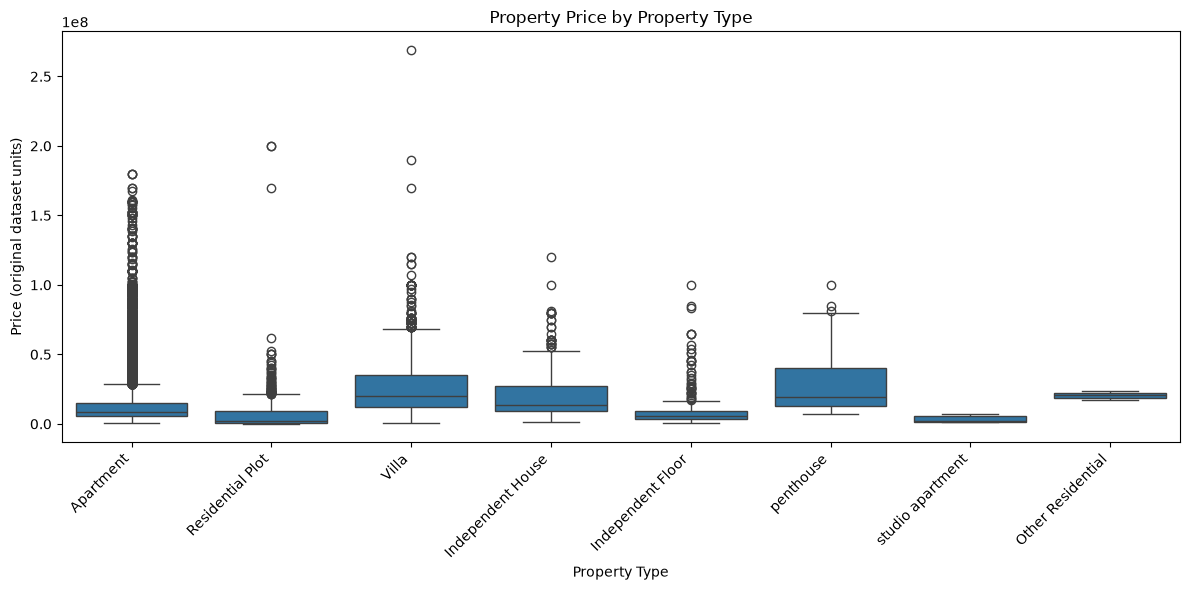

In [15]:

top_types = df["property_type"].value_counts().head(10).index

plt.figure(figsize=(12, 6))

sns.boxplot(
    data=df[df["property_type"].isin(top_types)],
    x="property_type",
    y="price"
)

plt.title("Property Price by Property Type")
plt.xlabel("Property Type")
plt.ylabel("Price (original dataset units)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [16]:

# Top 15 localities by number of listings
top_localities = df["locality"].value_counts().head(15).index

locality_summary = (
    df[df["locality"].isin(top_localities)]
    .groupby("locality")
    .agg(
        property_count=("price", "size"),
        median_price=("price", "median"),
        median_area=("area", "median")
    )
    .sort_values("property_count", ascending=False)
)

display(locality_summary.round(2))


,property_count,median_price,median_area
locality,,,
Kharadi,4327,"9,500,000.00","1,520.00"
Viman Nagar,3113,"10,500,000.00","1,385.00"
Kalyani Nagar,2880,"18,500,000.00","1,800.00"
Wagholi,2608,"4,932,269.00","1,049.00"
Koregaon Park,2257,"24,000,000.00","2,000.00"
Hadapsar,1308,"5,500,000.00",994.00
Baner,1002,"10,500,000.00","1,473.00"
Wakad,802,"7,800,000.00","1,200.00"
Hinjewadi,800,"6,800,000.00","1,260.00"


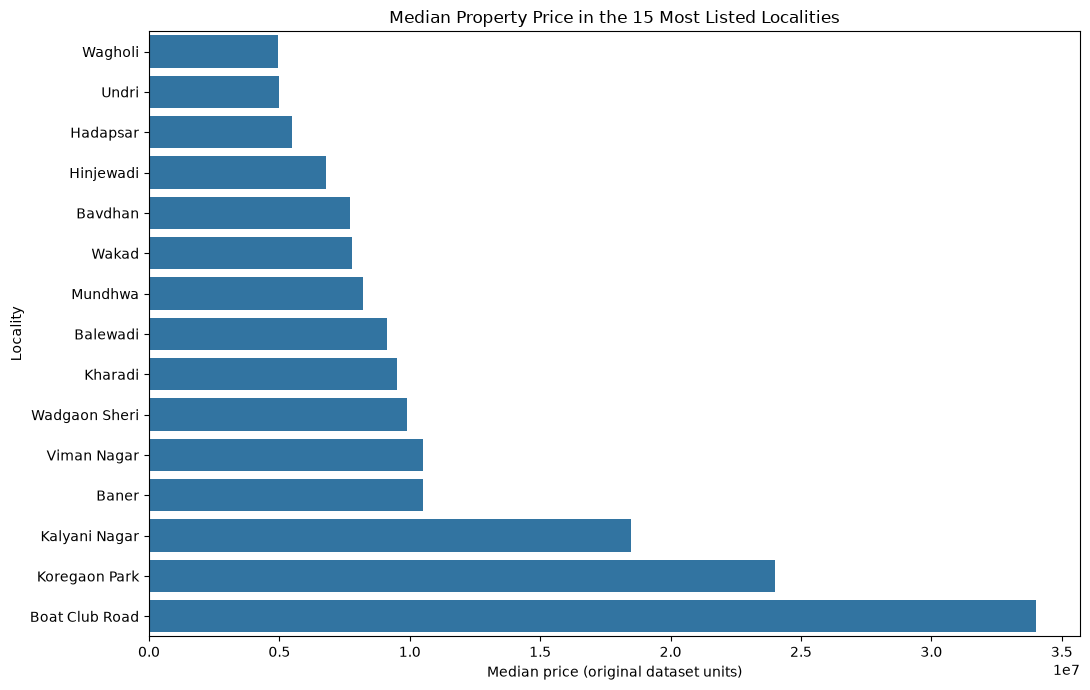

In [17]:

plot_data = locality_summary.sort_values("median_price")

plt.figure(figsize=(11, 7))

sns.barplot(
    data=plot_data.reset_index(),
    x="median_price",
    y="locality"
)

plt.title("Median Property Price in the 15 Most Listed Localities")
plt.xlabel("Median price (original dataset units)")
plt.ylabel("Locality")
plt.tight_layout()
plt.show()


In [18]:

# Count properties by BHK configuration
print("BHK count distribution:")
display(
    df["bhk"].value_counts(dropna=False).head(20).to_frame("property_count")
)

# Compare median prices by BHK count
bhk_summary = (
    df.dropna(subset=["bhk_count"])
    .groupby("bhk_count")
    .agg(
        property_count=("price", "size"),
        median_price=("price", "median"),
        median_area=("area", "median")
    )
    .sort_index()
)

display(bhk_summary.round(2))


BHK count distribution:


,property_count
bhk,
2 BHK Apartment,10871
3 BHK Apartment,8129
1 BHK Apartment,3498
4 BHK Apartment,3319
3 BHK Villa,691
Residential Plot,645
4 BHK Villa,600
5 BHK Apartment,521
2 BHK Villa,221


,property_count,median_price,median_area
bhk_count,,,
0.00,1,"15,000,000.00","4,300.00"
1.00,3679,"3,650,000.00",610.00
2.00,11378,"6,999,988.50","1,058.00"
3.00,9173,"12,600,000.00","1,661.00"
4.00,4083,"35,000,000.00","3,346.00"
5.00,685,"57,000,000.00","4,800.00"
6.00,29,"60,000,000.00","4,100.00"
7.00,4,"95,000,000.00","7,500.00"
8.00,3,"20,000,000.00","4,000.00"


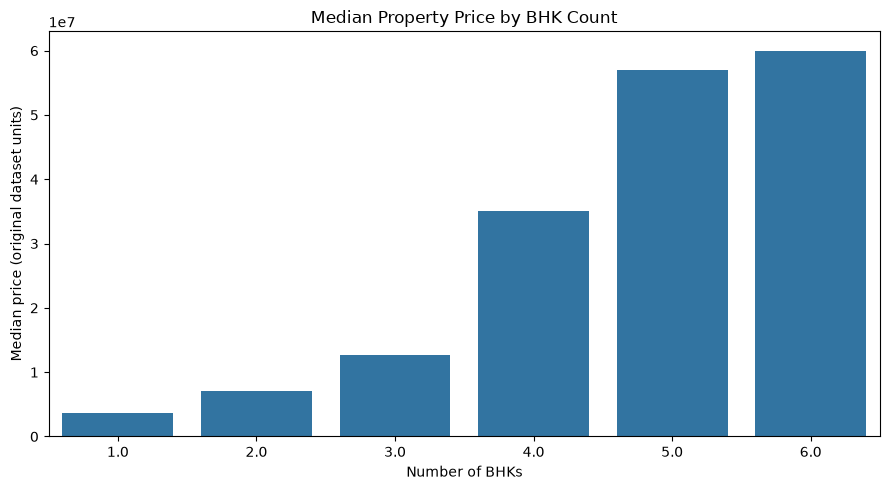

In [19]:

# Focus on BHK counts from 1 to 6 for a clearer comparison
bhk_plot = bhk_summary.loc[
    bhk_summary.index.isin([1, 2, 3, 4, 5, 6])
].reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(data=bhk_plot, x="bhk_count", y="median_price")

plt.title("Median Property Price by BHK Count")
plt.xlabel("Number of BHKs")
plt.ylabel("Median price (original dataset units)")
plt.tight_layout()
plt.show()


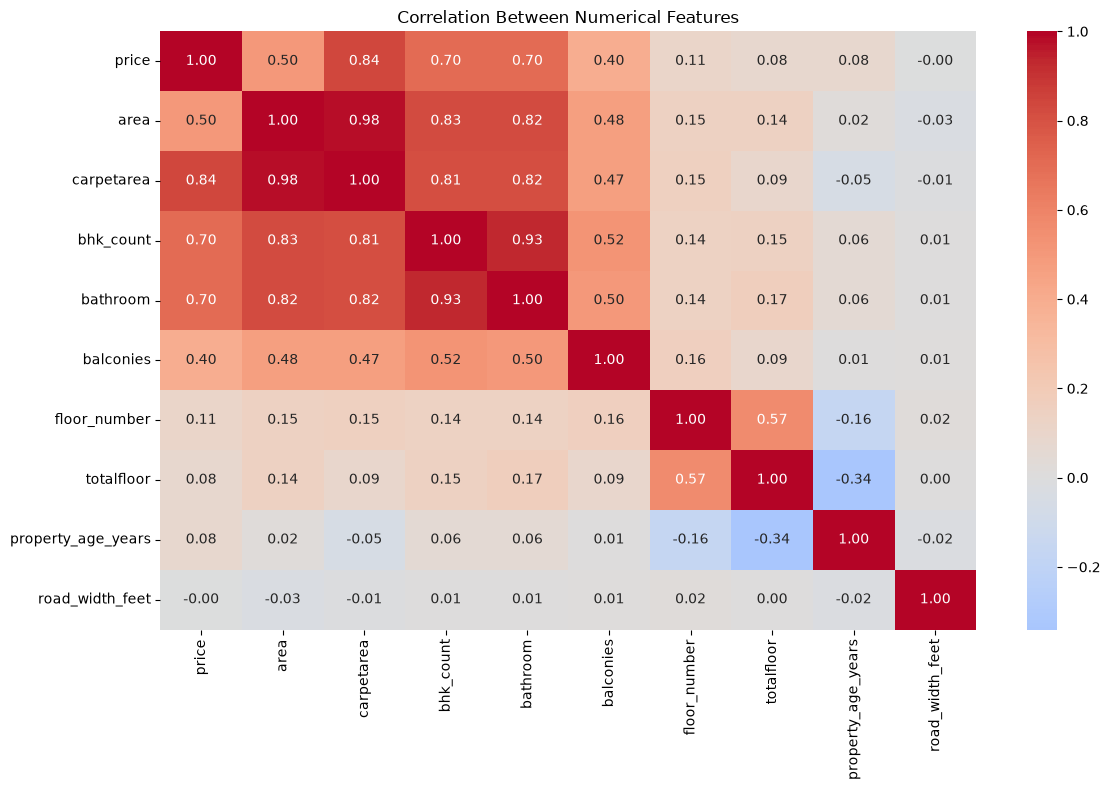

In [20]:

# Select numerical features for correlation analysis
numeric_features = [
    "price",
    "area",
    "carpetarea",
    "bhk_count",
    "bathroom",
    "balconies",
    "floor_number",
    "totalfloor",
    "property_age_years",
    "road_width_feet"
]

correlation_matrix = df[numeric_features].corr(numeric_only=True)

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Between Numerical Features")
plt.tight_layout()
plt.show()


In [21]:

display(
    df.loc[
        df["bhk_count"].eq(0),
        ["price", "area", "bhk", "property_type", "locality"]
    ]
)


,price,area,bhk,property_type,locality
4921,15000000,"4,300.00",0 BHK Villa,Villa,Wagholi


In [22]:

# Inspect the original record
zero_bhk = df.loc[
    df["bhk_count"].eq(0),
    ["price", "area", "bhk", "property_type", "locality"]
]

display(zero_bhk)

# Count unusual BHK values
print("Records with BHK count 0:", int(df["bhk_count"].eq(0).sum()))
print("Records with missing BHK count:", int(df["bhk_count"].isna().sum()))


,price,area,bhk,property_type,locality
4921,15000000,"4,300.00",0 BHK Villa,Villa,Wagholi


Records with BHK count 0: 1
Records with missing BHK count: 645


In [23]:

# Missing values across all columns
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percentage": (df.isna().mean() * 100).round(2),
    "data_type": df.dtypes.astype(str)
}).sort_values("missing_percentage", ascending=False)

display(missing_summary)

# Inspect all columns
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())


,missing_count,missing_percentage,data_type
possession_date,26231,88.38,str
possesiondate,26231,88.38,str
roadfaceing,24550,82.72,str
road_width_feet,24550,82.72,float64
carpetarea,23133,77.94,float64
additionalrooms,22363,75.35,str
opensides,21243,71.57,float64
overlooking,16121,54.32,str
balconies,11955,40.28,float64
projectname,10524,35.46,str


Dataset shape: (29680, 30)

Columns:
['additionalrooms', 'age', 'amenitiesavailable', 'amenitiesnot', 'area', 'balconies', 'bathroom', 'bhk', 'carpetarea', 'facing', 'floor', 'locality', 'neworold', 'opensides', 'overlooking', 'ownership', 'possesiondate', 'price', 'pricepersquare', 'projectname', 'roadfaceing', 'status', 'totalfloor', 'bhk_count', 'property_type', 'floor_number', 'road_width_feet', 'property_age_years', 'possession_date', 'price_group']
